# Patterned_surface 512×512 random inpainting

This notebook adapts the NFFA random-mask benchmark to the Patterned_surface 512×512 model. One model-sized image is inferred directly, with no tiling or blending. Inputs can be normalized `.npy` patches or 512×512 `.png` previews; the PNG path uses its paired center-crop percentiles when available.

Set `TEST_IMAGE_PATH = None` for a held-out Patterned_surface test NPY, or specify a processed NPY/PNG. `MISSING_FRACTION` defaults to 70%; set it to 90% for the earlier high-missingness test. `HARD_KNOWN_PIXEL_CONSISTENCY=True` reproduces the existing NFFA random notebook. Set it to `False` to retain a nonzero data-fit gradient during iteration; final known pixels can still be projected once at the end.


In [33]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    candidate = repo_root.parent
    if (candidate / 'pnpflow').is_dir():
        repo_root = candidate
    else:
        raise RuntimeError('Open from the PnP-Flow repository or its notebooks directory.')
os.chdir(repo_root)

DATASET_NAME = 'sem_nffa_all10_centerresize_512'
CLASS_NAME = 'Patterned_surface'
RUN_NAME = '20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep'
CHECKPOINT_NAME = 'model_final.pt'  # or model_N.pt / training_state_latest.pt
TEST_SAMPLE_INDEX = 0
TEST_IMAGE_PATH = None  # .npy or 512x512 .png; None selects a held-out class test NPY
TEST_IMAGE_PATH = '/data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_5d763f0aade2ad8ca626a0e9f437263f.npy'

PNG_REFERENCE_CROP_PATH = None  # paired center-crop PNG for an arbitrary 512x512 PNG

MISSING_FRACTION = 0.80  # set to 0.90 for the earlier high-missingness experiment
MASK_SEED = 42
NOISE_SEED = 0
SOLVER_SEED = 0
SEED = 0  # input/model initialization seed used by the shared loader
ADD_OBSERVATION_NOISE = True
HARD_KNOWN_PIXEL_CONSISTENCY = True  # matches the existing NFFA random notebook
FINAL_KNOWN_PIXEL_PROJECTION = True  # useful when HARD_KNOWN_PIXEL_CONSISTENCY=False
NOISE_STD = 0.01
STEPS_PNP = 100
NUM_SAMPLES = 5
LR_PNP = 1.0
ALPHA = 0.01
ZOOM_TOP = 160
ZOOM_LEFT = 160
ZOOM_SIZE = 192
SEED = 0

checkpoint_path = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / CHECKPOINT_NAME
processed_root = repo_root / 'data' / DATASET_NAME
test_root = processed_root / 'test' / CLASS_NAME
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'Checkpoint not found: {checkpoint_path}')
test_files = sorted(test_root.glob('*.npy'))
if not test_files:
    raise FileNotFoundError(f'No {CLASS_NAME} test patches under {test_root}')
if TEST_IMAGE_PATH is None:
    if not 0 <= TEST_SAMPLE_INDEX < len(test_files):
        raise IndexError(f'TEST_SAMPLE_INDEX={TEST_SAMPLE_INDEX}; found {len(test_files)} test patches.')
    patch_path = test_files[TEST_SAMPLE_INDEX]
else:
    patch_path = Path(TEST_IMAGE_PATH).expanduser()
    if not patch_path.is_absolute():
        patch_path = repo_root / patch_path
    patch_path = patch_path.resolve()
    if not patch_path.is_file():
        matches = [processed_root / split / CLASS_NAME / patch_path.name
                   for split in ('train', 'val', 'test')
                   if (processed_root / split / CLASS_NAME / patch_path.name).is_file()]
        hint = f' The file exists under {matches[0]}' if matches else ''
        raise FileNotFoundError(f'Input image not found: {patch_path}.{hint}')
    if patch_path.suffix.lower() not in {'.npy', '.png'}:
        raise ValueError(f'Expected a processed .npy or .png image, got {patch_path}')

split_matches = [split for split in ('train', 'val', 'test')
                 if (processed_root / split / CLASS_NAME / f'{patch_path.stem}.npy').is_file()]
input_split = split_matches[0] if len(split_matches) == 1 else 'unknown'

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)

print(f'Checkpoint: {checkpoint_path}')
print(f'{CLASS_NAME} held-out test patches available: {len(test_files)}')
print(f'Selected input: {patch_path}; split: {input_split}')
if input_split == 'train':
    print('Warning: this is a training image; its masked PSNR is not a held-out evaluation.')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(device)}')

Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10_centerresize_512/ot/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/model_final.pt
Patterned_surface held-out test patches available: 476
Selected input: /data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_5d763f0aade2ad8ca626a0e9f437263f.npy; split: test
Device: cuda:0
GPU: Tesla V100-SXM2-32GB


In [34]:
from pnpflow.utils import define_model

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = 512

model, _ = define_model(ModelArgs())
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
state_dict = checkpoint.get('model_state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
model.load_state_dict(state_dict, strict=True)
model.to(device).eval()
if any(not torch.isfinite(p).all().item() for p in model.parameters()):
    raise ValueError(f'Checkpoint contains non-finite parameters: {checkpoint_path}')

image_format = patch_path.suffix.lower().lstrip('.')
normalization_reference = 'stored normalized NPY'
normalization_low_high = None
clean_root = processed_root.resolve().parents[2]
if image_format == 'npy':
    patch = np.load(patch_path, allow_pickle=False).astype(np.float32)
    if patch.ndim == 3 and patch.shape[0] == 1:
        patch = patch[0]
    if not np.isfinite(patch).all() or patch.min() < -1.001 or patch.max() > 1.001:
        raise ValueError(f'Expected a normalized finite NPY in [-1, 1], got {patch_path}')
else:
    with Image.open(patch_path) as handle:
        if handle.size != (512, 512):
            preview = clean_root / 'centercrop_resized' / 'resized' / 'images' / CLASS_NAME / patch_path.name
            hint = f' Use the 512x512 preview at {preview}' if preview.is_file() else ''
            raise ValueError(f'Expected a 512x512 PNG, got {handle.size} from {patch_path}.{hint}')
        pixels = np.asarray(handle.convert('L'), dtype=np.uint8)
    preview_root = clean_root / 'centercrop_resized' / 'resized' / 'images'
    if PNG_REFERENCE_CROP_PATH is not None:
        reference_path = Path(PNG_REFERENCE_CROP_PATH).expanduser()
        if not reference_path.is_absolute():
            reference_path = repo_root / reference_path
        reference_path = reference_path.resolve()
        if not reference_path.is_file():
            raise FileNotFoundError(f'PNG normalization reference not found: {reference_path}')
    else:
        try:
            relative = patch_path.resolve().relative_to(preview_root.resolve())
            reference_path = clean_root / 'centercrop' / relative
        except ValueError:
            reference_path = None
    if reference_path is not None and reference_path.is_file():
        with Image.open(reference_path) as handle:
            reference = np.asarray(handle.convert('L'), dtype=np.uint8)
        normalization_reference = str(reference_path)
    else:
        reference = pixels
        normalization_reference = 'input PNG percentiles (no paired center crop found)'
        print('Warning: no paired center crop found; PNG normalization may differ from training.')
    low, high = np.percentile(reference.astype(np.float32), (1, 99))
    if not high > low:
        raise ValueError(f'PNG normalization has no usable intensity range: [{low}, {high}]')
    patch = (2.0 * np.clip((pixels.astype(np.float32) - low) / (high - low), 0, 1) - 1.0)
    patch = patch.astype(np.float16).astype(np.float32)  # match stored training NPY quantization
    normalization_low_high = [float(low), float(high)]

if patch.shape != (512, 512) or not np.isfinite(patch).all():
    raise ValueError(f'Expected a finite 512 x 512 image, got {patch.shape} from {patch_path}')
clean = torch.from_numpy(patch)[None, None].to(device=device)
print(f'Loaded {image_format.upper()} input with shape {tuple(clean.shape)}')
print(f'Normalization source: {normalization_reference}')
print(f'Normalized range: {clean.min().item():.3f} to {clean.max().item():.3f}')

Loaded NPY input with shape (1, 1, 512, 512)
Normalization source: stored normalized NPY
Normalized range: -1.000 to 1.000


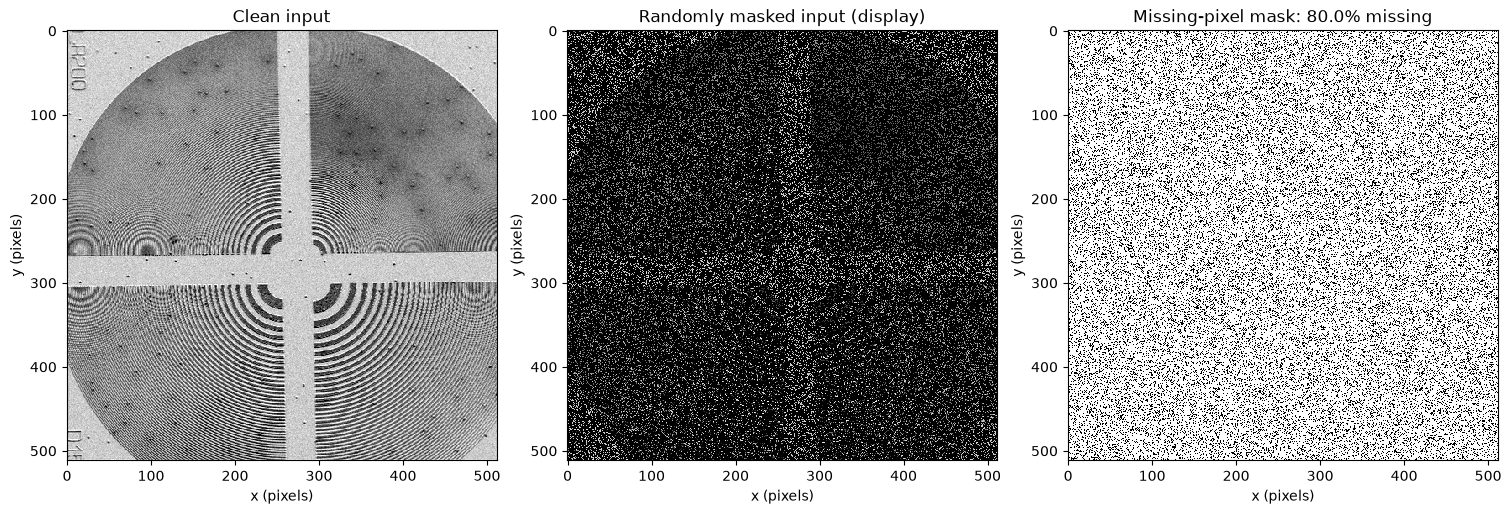

Image size: Y=512, X=512
Missing pixels: 209,749/262,144 (80.01%)
Observed pixels: 52,395


In [35]:
if not 0.0 < MISSING_FRACTION < 1.0:
    raise ValueError('MISSING_FRACTION must be strictly between 0 and 1.')
if STEPS_PNP < 1 or NUM_SAMPLES < 1 or NOISE_STD <= 0:
    raise ValueError('STEPS_PNP, NUM_SAMPLES, and NOISE_STD must be positive.')

clean_np = clean[0, 0].cpu().numpy()
mask_rng = np.random.default_rng(MASK_SEED)
missing_np = mask_rng.random(clean_np.shape) < MISSING_FRACTION
known_np = ~missing_np
if not missing_np.any() or not known_np.any():
    raise ValueError('The random mask needs both missing and observed pixels.')

observed_np = np.zeros_like(clean_np, dtype=np.float32)
if ADD_OBSERVATION_NOISE:
    noise_rng = np.random.default_rng(NOISE_SEED)
    noise = noise_rng.normal(0.0, NOISE_STD, clean_np.shape).astype(np.float32)
    observed_np[known_np] = np.clip(clean_np[known_np] + noise[known_np], -1.0, 1.0)
else:
    observed_np[known_np] = clean_np[known_np]
observed_display = observed_np.copy()
observed_display[missing_np] = -1.0  # display only: visibly mark missing pixels black

known = torch.from_numpy(known_np.astype(np.float32))[None, None].to(device)
observed = torch.from_numpy(observed_np)[None, None].to(device)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(clean_np, cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
axes[0].set_title('Clean input')
axes[1].imshow(observed_display, cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
axes[1].set_title('Randomly masked input (display)')
axes[2].imshow(missing_np, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[2].set_title(f'Missing-pixel mask: {missing_np.mean():.1%} missing')
for ax in axes:
    ax.set_xlabel('x (pixels)')
    ax.set_ylabel('y (pixels)')
plt.show()
print(f'Image size: Y={clean_np.shape[0]}, X={clean_np.shape[1]}')
print(f'Missing pixels: {missing_np.sum():,}/{missing_np.size:,} ({missing_np.mean():.2%})')
print(f'Observed pixels: {known_np.sum():,}')

In [36]:
@torch.inference_mode()
def pnp_flow_random_inpaint(model, observed, known):
    known = known.to(device=observed.device, dtype=observed.dtype)
    x = known * observed
    lr = NOISE_STD ** 2 * LR_PNP

    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), iteration / STEPS_PNP, device=x.device, dtype=x.dtype)
        t_view = t.view(-1, 1, 1, 1)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(-1, 1, 1, 1)
        data_gradient = known * (known * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient

        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            z_tilde = t_view * z + (1.0 - t_view) * torch.randn_like(z)
            velocity = model(z_tilde, t)
            x_new += z_tilde + (1.0 - t_view) * velocity
        x_new /= NUM_SAMPLES

        x = known * observed + (1.0 - known) * x_new if HARD_KNOWN_PIXEL_CONSISTENCY else x_new
        if (iteration + 1) % 20 == 0 or iteration == 0:
            print(f'PnP iteration {iteration + 1}/{STEPS_PNP}')

    if FINAL_KNOWN_PIXEL_PROJECTION:
        x = known * observed + (1.0 - known) * x
    return x.clamp(-1.0, 1.0)

torch.manual_seed(SOLVER_SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SOLVER_SEED)
start = time.perf_counter()
reconstruction = pnp_flow_random_inpaint(model, observed, known)
if device.type == 'cuda':
    torch.cuda.synchronize(device)
inference_seconds = time.perf_counter() - start
reconstruction_np = reconstruction[0, 0].cpu().numpy()
print(f'Inpainting finished in {inference_seconds:.1f} seconds')

PnP iteration 1/100
PnP iteration 20/100
PnP iteration 40/100
PnP iteration 60/100
PnP iteration 80/100
PnP iteration 100/100
Inpainting finished in 100.7 seconds


checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10_centerresize_512/ot/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/model_final.pt
input_path: /data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_5d763f0aade2ad8ca626a0e9f437263f.npy
input_split: test
input_format: npy
normalization_source: stored normalized NPY
normalization_low_high: None
mask_seed: 42
noise_seed: 0
solver_seed: 0
missing_fraction_requested: 0.8
missing_fraction_actual: 0.8001289367675781
add_observation_noise: True
hard_known_pixel_consistency: True
final_known_pixel_projection: True
noise_std: 0.01
steps_pnp: 100
num_samples: 5
lr_pnp: 1.0
alpha: 0.01
masked_psnr_db: 19.45545240653165
zero_fill_masked_psnr_db: 12.972420634439196
masked_mae_normalized: 0.15468263626098633
full_psnr_db: 20.4214770835488
maximum_known_consistency_error: 0.0
inference_seconds: 100.7286956938915


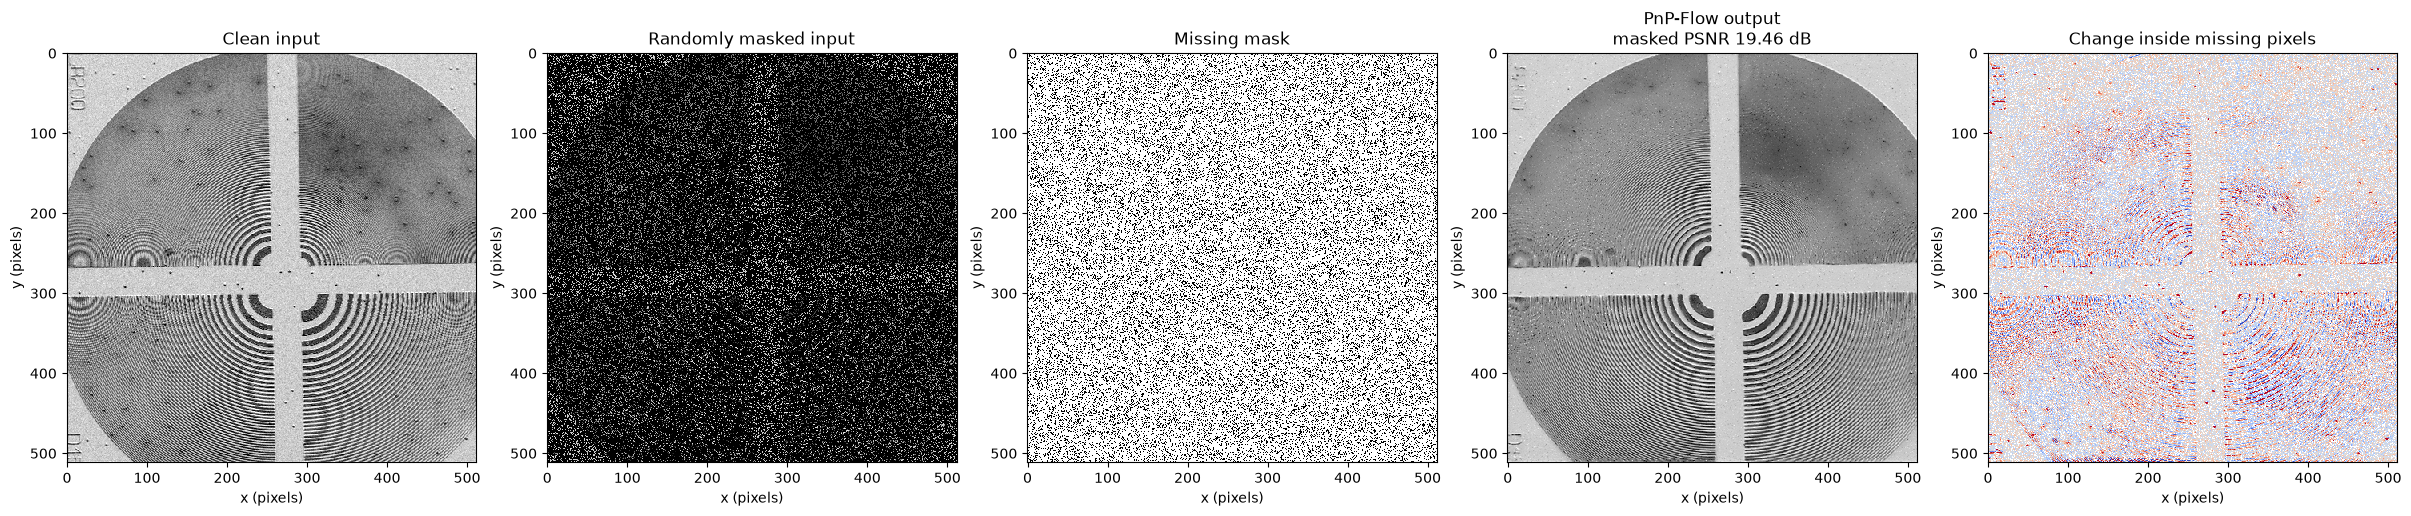

In [37]:
error = reconstruction_np - clean_np
masked_mse = float(np.mean(error[missing_np] ** 2))
zero_fill_mse = float(np.mean(clean_np[missing_np] ** 2))
masked_mae = float(np.mean(np.abs(error[missing_np])))
masked_psnr = float(10.0 * np.log10(4.0 / max(masked_mse, 1e-12)))
zero_fill_psnr = float(10.0 * np.log10(4.0 / max(zero_fill_mse, 1e-12)))
full_mse = float(np.mean(error ** 2))
full_psnr = float(10.0 * np.log10(4.0 / max(full_mse, 1e-12)))
known_consistency = float(np.max(np.abs(reconstruction_np[known_np] - observed_np[known_np])))
change_inside_mask = np.where(missing_np, error, np.nan)
change_limit = max(float(np.nanpercentile(np.abs(change_inside_mask), 99)), 1e-6)

metrics = {
    'checkpoint': str(checkpoint_path),
    'input_path': str(patch_path),
    'input_split': input_split,
    'input_format': image_format,
    'normalization_source': normalization_reference,
    'normalization_low_high': normalization_low_high,
    'mask_seed': MASK_SEED,
    'noise_seed': NOISE_SEED,
    'solver_seed': SOLVER_SEED,
    'missing_fraction_requested': MISSING_FRACTION,
    'missing_fraction_actual': float(missing_np.mean()),
    'add_observation_noise': ADD_OBSERVATION_NOISE,
    'hard_known_pixel_consistency': HARD_KNOWN_PIXEL_CONSISTENCY,
    'final_known_pixel_projection': FINAL_KNOWN_PIXEL_PROJECTION,
    'noise_std': NOISE_STD,
    'steps_pnp': STEPS_PNP,
    'num_samples': NUM_SAMPLES,
    'lr_pnp': LR_PNP,
    'alpha': ALPHA,
    'masked_psnr_db': masked_psnr,
    'zero_fill_masked_psnr_db': zero_fill_psnr,
    'masked_mae_normalized': masked_mae,
    'full_psnr_db': full_psnr,
    'maximum_known_consistency_error': known_consistency,
    'inference_seconds': inference_seconds,
}
for key, value in metrics.items():
    print(f'{key}: {value}')

fig, axes = plt.subplots(1, 5, figsize=(24, 5), constrained_layout=True)
panels = [
    (clean_np, 'Clean input', 'gray', -1, 1),
    (observed_display, 'Randomly masked input', 'gray', -1, 1),
    (missing_np, 'Missing mask', 'gray', 0, 1),
    (reconstruction_np, f'PnP-Flow output\nmasked PSNR {masked_psnr:.2f} dB', 'gray', -1, 1),
    (change_inside_mask, 'Change inside missing pixels', 'coolwarm', -change_limit, change_limit),
]
for ax, (image, title, cmap, vmin, vmax) in zip(axes, panels):
    ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('x (pixels)')
    ax.set_ylabel('y (pixels)')
plt.show()

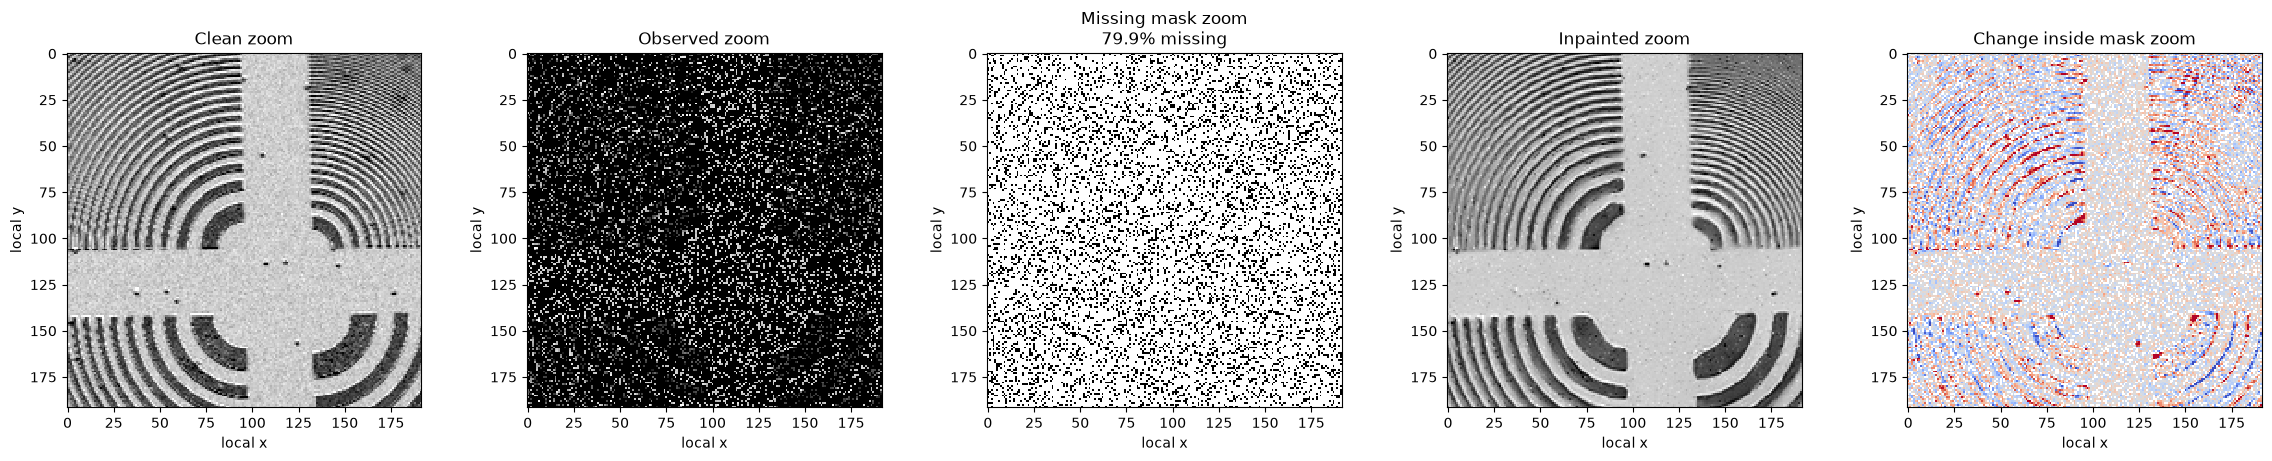

Saved full comparison: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/Patterned_surface/random_inpainting/test_L1_5d763f0aade2ad8ca626a0e9f437263f/comparison.png
Saved zoom comparison: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/Patterned_surface/random_inpainting/test_L1_5d763f0aade2ad8ca626a0e9f437263f/zoom_comparison.png
Saved metrics: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/Patterned_surface/random_inpainting/test_L1_5d763f0aade2ad8ca626a0e9f437263f/metrics.json


In [38]:
height, width = clean_np.shape
if not (0 <= ZOOM_TOP < height and 0 <= ZOOM_LEFT < width and ZOOM_SIZE > 0):
    raise ValueError('The zoom origin and size must lie inside the image.')
zoom_bottom = min(height, ZOOM_TOP + ZOOM_SIZE)
zoom_right = min(width, ZOOM_LEFT + ZOOM_SIZE)
zoom = np.s_[ZOOM_TOP:zoom_bottom, ZOOM_LEFT:zoom_right]

fig_zoom, axes = plt.subplots(1, 5, figsize=(23, 4.5), constrained_layout=True)
zoom_panels = [
    (clean_np[zoom], 'Clean zoom', 'gray', -1, 1),
    (observed_display[zoom], 'Observed zoom', 'gray', -1, 1),
    (missing_np[zoom], f'Missing mask zoom\n{missing_np[zoom].mean():.1%} missing', 'gray', 0, 1),
    (reconstruction_np[zoom], 'Inpainted zoom', 'gray', -1, 1),
    (change_inside_mask[zoom], 'Change inside mask zoom', 'coolwarm', -change_limit, change_limit),
]
for ax, (image, title, cmap, vmin, vmax) in zip(axes, zoom_panels):
    ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('local x')
    ax.set_ylabel('local y')
plt.show()

output_dir = repo_root / 'notebooks' / 'outputs' / RUN_NAME / CLASS_NAME / 'random_inpainting' / f'{input_split}_{patch_path.stem}'
output_dir.mkdir(parents=True, exist_ok=True)
comparison_path = output_dir / 'comparison.png'
zoom_path = output_dir / 'zoom_comparison.png'
metrics_path = output_dir / 'metrics.json'
fig.savefig(comparison_path, dpi=160, bbox_inches='tight')
fig_zoom.savefig(zoom_path, dpi=160, bbox_inches='tight')
np.save(output_dir / 'missing_mask_uint8.npy', missing_np.astype(np.uint8))
np.save(output_dir / 'observed_normalized_float32.npy', observed_np.astype(np.float32))
np.save(output_dir / 'reconstruction_normalized_float32.npy', reconstruction_np.astype(np.float32))
metrics_path.write_text(json.dumps(metrics, indent=2) + '\n')
print(f'Saved full comparison: {comparison_path}')
print(f'Saved zoom comparison: {zoom_path}')
print(f'Saved metrics: {metrics_path}')